# Do Income Features Improve Rent Prediction?

**Data:** real (Dwellsy) + Census ACS

**Inputs:** `chicago_income_enriched.csv`

**Outputs:** `outputs/income/income_model_comparison.csv`, `outputs/income/income_model_comparison.png`

**Run after:** `01_income_features.ipynb`

Two evaluations:

1. **Standard split:** the same group split by `uru_id` as notebook 05. ZIPs seen in training also appear in test, so ZIP-level information is already available to the models through `address_zip`.
2. **Held-out ZIPs:** whole ZIPs are withheld for testing. Here the model cannot learn the ZIP, so a neighbourhood income value is the kind of signal that should help most.

The baseline rows should match the notebook 05 validation results; that is the check that nothing else changed.

In [1]:
seed = 710

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "libs").is_dir())
sys.path.insert(0, str(ROOT))          # shared libs/ package
sys.path.insert(0, str(Path.cwd()))    # income.py and rent_models.py in this folder

from libs import paths
import income, rent_models

In [3]:
df = pd.read_csv(
    paths.PROCESSED / "chicago_income_enriched.csv",
    dtype={"address_zip": "string"},
    parse_dates=["creation_time"],
    low_memory=False,
)
print("Listings:", df.shape, "| with income:", f"{df[income.INCOME_COLUMN].notna().mean():.1%}")

BASE_NUM, CAT = rent_models.BASE_NUMERIC, rent_models.BASE_CATEGORICAL
INCOME_NUM = BASE_NUM + [income.INCOME_COLUMN, income.MISSING_FLAG]

Listings: (545312, 51) | with income: 100.0%


## 1. Standard group split (same as notebook 05)

In [4]:
split = rent_models.make_split(df, seed=seed)
print({k: len(v) for k, v in split.items()})

standard = pd.concat([
    rent_models.run_models(df, split, BASE_NUM, CAT, "baseline", seed),
    rent_models.run_models(df, split, INCOME_NUM, CAT, "+ income", seed),
], ignore_index=True)
standard["Split"] = "standard"

{'train': 348494, 'val': 87942, 'test': 108876}


## 2. Held-out ZIP split

In [5]:
zip_split = rent_models.make_zip_holdout_split(df, seed=seed)
test_zips = set(df["address_zip"].iloc[zip_split["test"]])
train_zips = set(df["address_zip"].iloc[zip_split["train"]])
assert test_zips.isdisjoint(train_zips)
print({k: len(v) for k, v in zip_split.items()}, "| test ZIPs:", len(test_zips))

heldout = pd.concat([
    rent_models.run_models(df, zip_split, BASE_NUM, CAT, "baseline", seed),
    rent_models.run_models(df, zip_split, INCOME_NUM, CAT, "+ income", seed),
], ignore_index=True)
heldout["Split"] = "held-out ZIPs"

{'train': 329671, 'val': 82472, 'test': 133169} | test ZIPs: 76


## 3. Compare

In [6]:
results = pd.concat([standard, heldout], ignore_index=True)
metrics = ["MAE", "RMSE", "R²", "MdAPE"]

wide = results.pivot_table(index=["Split", "Eval", "Model"], columns="Features", values=metrics)
delta = pd.DataFrame(index=wide.index)
for m in metrics:
    delta[f"{m} baseline"] = wide[(m, "baseline")]
    delta[f"{m} + income"] = wide[(m, "+ income")]
    delta[f"{m} change"] = wide[(m, "+ income")] - wide[(m, "baseline")]

# For MAE, RMSE and MdAPE a negative change is an improvement; for R² a positive one is.
display(delta.round(4))

out_dir = paths.output_dir() / "income"
out_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(out_dir / "income_model_comparison.csv", index=False)

MAE baseline  MAE + income  MAE change  \
Split         Eval Model                                                       
held-out ZIPs test Decision Tree          506.2318      475.1198    -31.1120   
                   Gradient Boosting      658.5401      619.7165    -38.8237   
                   Linear Regression      737.6629      444.6665   -292.9965   
                   Random Forest          513.3986      507.6925     -5.7061   
              val  Decision Tree          328.1745      288.1747    -39.9999   
                   Gradient Boosting      219.5667      220.0643      0.4976   
                   Linear Regression      329.4280      397.8062     68.3783   
                   Random Forest          274.9131      224.2846    -50.6285   
standard      test Decision Tree          355.0773      305.6778    -49.3995   
                   Gradient Boosting      229.1764      227.5856     -1.5908   
                   Linear Regression      334.1952      398.7815     64.5863   
                   Random Forest          298.0278      238.2031    -59.8247   
              val  Decision Tree          345.7916      297.7594    -48.0322   
                   Gradient Boosting      229.2215      227.8434     -1.3781   
                   Linear Regression      334.6195      404.8999     70.2804   
                   Random Forest          291.1663      231.9681    -59.1982   

                                      RMSE baseline  RMSE + income  \
Split         Eval Model                                             
held-out ZIPs test Decision Tree           811.6227       814.2380   
                   Gradient Boosting       980.0276       949.0125   
                   Linear Regression      1021.4961       723.3755   
                   Random Forest           829.3405       849.7676   
              val  Decision Tree           502.5582       462.0592   
                   Gradient Boosting       367.1645       366.0045   
                   Linear Regression       522.4489       607.2084   
                   Random Forest           430.8009       383.6754   
standard      test Decision Tree           546.5987       524.4646   
                   Gradient Boosting       387.8495       381.6798   
                   Linear Regression       524.8778       604.3631   
                   Random Forest           460.7820       444.9334   
              val  Decision Tree           533.1118       485.0961   
                   Gradient Boosting       396.2369       392.4799   
                   Linear Regression       551.7351       636.7360   
                   Random Forest           464.5831       408.8622   

                                      RMSE change  R² baseline  R² + income  \
Split         Eval Model                                                      
held-out ZIPs test Decision Tree           2.6153       0.4106       0.4068   
                   Gradient Boosting     -31.0150       0.1406       0.1941   
                   Linear Regression    -298.1206       0.0663       0.5318   
                   Random Forest          20.4272       0.3845       0.3539   
              val  Decision Tree         -40.4990       0.7186       0.7621   
                   Gradient Boosting      -1.1600       0.8498       0.8507   
                   Linear Regression      84.7595       0.6959       0.5892   
                   Random Forest         -47.1256       0.7932       0.8360   
standard      test Decision Tree         -22.1340       0.6730       0.6989   
                   Gradient Boosting      -6.1696       0.8354       0.8406   
                   Linear Regression      79.4853       0.6985       0.6002   
                   Random Forest         -15.8486       0.7676       0.7833   
              val  Decision Tree         -48.0157       0.6979       0.7498   
                   Gradient Boosting      -3.7570       0.8331       0.8362   
                   Linear Regression      85.0009       0.6764       0.5

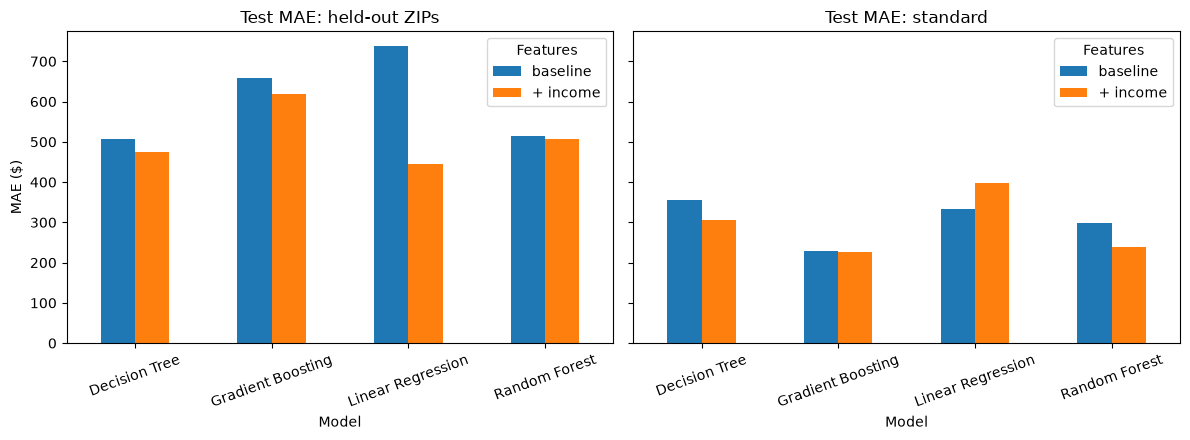

In [7]:
test_rows = results[results["Eval"] == "test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, part) in zip(axes, test_rows.groupby("Split")):
    pivot = part.pivot(index="Model", columns="Features", values="MAE")[["baseline", "+ income"]]
    pivot.plot.bar(ax=ax, rot=20)
    ax.set_title(f"Test MAE: {name}")
    ax.set_ylabel("MAE ($)")
fig.tight_layout()
fig.savefig(out_dir / "income_model_comparison.png", dpi=150)
plt.show()

## 4. Reading the results

-Standard split didn't have much change
-Held-out ZIPs had some improvement
-Most improvement on the linear regression model